# Missing company information: is it random?

company_size and company_type are the two columns with the most missing values (about 31 % and 32 %). Before we fill these gaps we need to know **why** they are missing, because that decides which method is safe.

This notebook checks one question: **does the missing company information depend on relevant_experience?**

It uses the converted data from `fix_data.ipynb` (`customer_train_typed.pkl`), so run that notebook first.

## Why the reason for missing values matters

There are three types of missing values:

| Type | Meaning | What it means for us |
|---|---|---|
| MCAR (missing completely at random) | missingness has nothing to do with the data | dropping or simple filling adds no bias |
| MAR (missing at random) | missingness depends on other columns we can see | fill the gaps using these other columns |
| MNAR (missing not at random) | missingness depends on the missing value itself | every simple fix biases the result, the missingness itself is information |

If people without relevant experience leave the company fields empty much more often, the values are **not** missing completely at random. Then filling them with the most common value (mode imputation) would distort the data.

Careful: a test can show that data are not MCAR, but it can never prove MCAR. MAR vs. MNAR needs domain knowledge.

## 1. Loading the data

We load the pickle file, so all data types from `fix_data.ipynb` are already there. `relevant_experience` is a bool column (True = has relevant experience).

We work on a copy, so the loaded data stays as it is.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

ds_jobs = pd.read_pickle("customer_train_typed.pkl")

# Create a copy
ds_jobs_transformed = ds_jobs.copy()

## 2. Method

For each of the two columns the code does four things:

1. **Missingness indicator:** a new column that is 1 if the value is missing and 0 if not. This turns "is it missing?" into something we can count.
2. **Crosstab:** a table that counts how often each combination occurs, e.g. "no relevant experience and company_size missing".
3. **Chi-square test:** checks if the two variables are independent.
   - Null hypothesis: missingness and relevant_experience have nothing to do with each other.
   - The p-value is the probability of seeing a difference this large if the null hypothesis were true.
   - If p is below 0.05, we reject the null hypothesis: missingness depends on relevant_experience.
4. **Bar chart:** the share of missing values for students with and without relevant experience. The test tells us **whether** there is a difference, the chart shows **how big** it is.

A small example of the crosstab for company_size, before the full analysis:

In [2]:
pd.crosstab(
    ds_jobs_transformed["relevant_experience"],
    ds_jobs_transformed["company_size"].isna(),
    rownames=["relevant experience"],
    colnames=["company_size missing"],
)

company_size missing,False,True
relevant experience,,
False,2009,3357
True,11211,2581


## 3. Analysis

The loop runs the four steps for company_size and company_type and draws one chart per column. The p-value is shown in the chart title and printed below.

`zip(axes, columns)` pairs each chart area with one column, so the first column is drawn on the left and the second on the right.

company_size: Chi² = 3470.37, p = 0.000e+00
company_type: Chi² = 2474.19, p = 0.000e+00


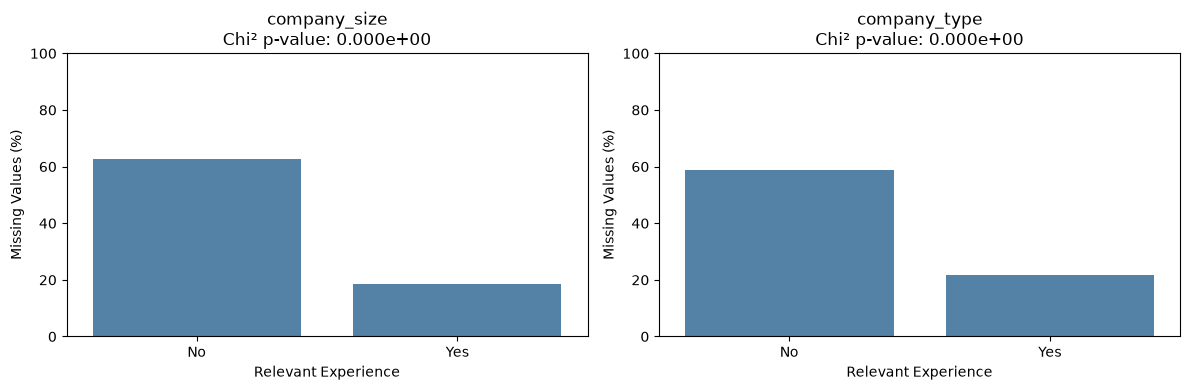

In [3]:
# Variables to analyze
columns = ["company_size", "company_type"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, columns):

    # Missingness indicator
    ds_jobs_transformed[f"{col}_missing"] = (
        ds_jobs_transformed[col].isna().astype(int)
    )

    # Chi-square test
    table = pd.crosstab(
        ds_jobs_transformed["relevant_experience"],
        ds_jobs_transformed[f"{col}_missing"]
    )

    chi2, p, _, _ = chi2_contingency(table)

    # Missing percentage by experience
    missing_pct = (
        ds_jobs_transformed.groupby("relevant_experience")
        [f"{col}_missing"].mean() * 100
    )
    # relevant_experience is bool, so show readable labels instead of False / True
    missing_pct.index = missing_pct.index.map({False: "No", True: "Yes"})

    sns.barplot(
        x=missing_pct.index,
        y=missing_pct.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"{col}\nChi² p-value: {p:.3e}")
    ax.set_xlabel("Relevant Experience")
    ax.set_ylabel("Missing Values (%)")
    ax.set_ylim(0, 100)

    print(f"{col}: Chi² = {chi2:.2f}, p = {p:.3e}")

plt.tight_layout()
plt.show()

## 4. Reading the result

- **p-value:** far below 0.05 means the missingness clearly depends on relevant_experience.
- **Bars:** the higher bar shows the group where company information is missing more often.
- With 19,158 rows even small differences become significant, so always look at the size of the difference in the chart as well, not only at p.

## 5. Conclusion

The missing values in company_size and company_type are **not missing completely at random**, they are connected to relevant_experience. A plausible reason: many people without relevant experience don't have a current employer, so there is no company to describe.

That's why we don't use mode imputation here. Filling every gap with the most common value ("Pvt Ltd", "50-99") would give students without a job a company they don't have.

Better options for the next step:

- a separate category like "Unknown" or "No company", so the information "missing" is kept
- keeping the `_missing` indicator as an extra feature for the model